# Mosaico panorámico con SIFT + Homografías

Construye un mosaico a partir de **N imágenes** con solape, usando SIFT para encontrar correspondencias y homografías para alinearlas.

Idea general: se parte de la primera imagen como "mosaico base" y, una a una, se van agregando las imágenes siguientes. Para cada imagen nueva se hace matching SIFT **contra el mosaico acumulado** (no contra la imagen original aislada), se calcula la homografía con RANSAC y se hace `warpPerspective` expandiendo el canvas para no perder contenido.

In [8]:
# to run in google colab
import sys

if "google.colab" in sys.modules:
    import subprocess

    subprocess.call("pip install -U opencv-python".split())
    subprocess.call(
        "wget -q -O mosaico.zip https://www.dropbox.com/scl/fi/fo6ptkhhkhfz7pv4lamsk/mosaico.zip?rlkey=egep1rflf2tj7ugnm8hnqs819&st=jgcw759t&dl=0".split()
    )
    subprocess.call("unzip -qq -o mosaico.zip".split())
    subprocess.call("rm mosaico.zip".split())

In [9]:
import os
import glob
import matplotlib.pyplot as plt
import numpy as np
import cv2

figsize = (12, 12)

## 1. Cargar las imágenes en orden

**Importante:** la lista `rutas` debe estar en el orden físico real en que se conectan las fotos (de izquierda a derecha, o como las tomaste), con buen solape (~30-50%) entre consecutivas. Ajusta los nombres de archivo a los tuyos.

12 imágenes cargadas


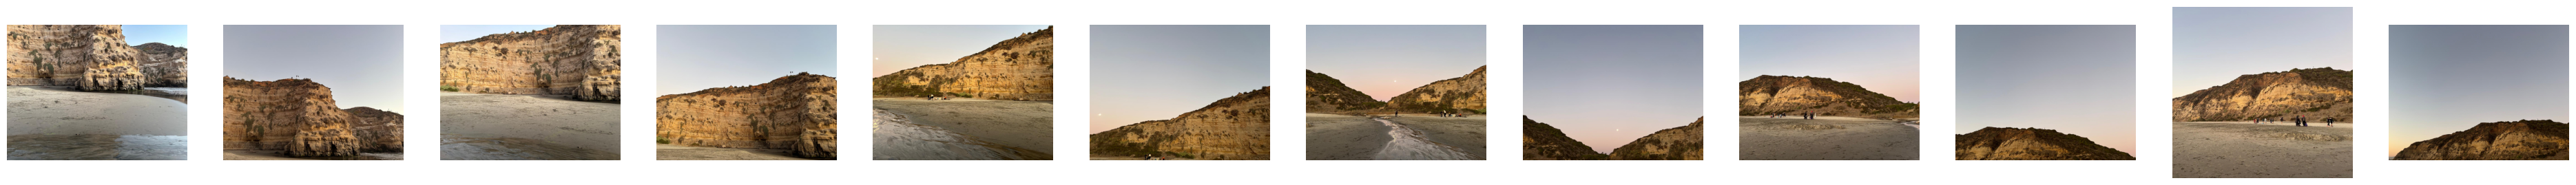

In [18]:
# Opción A: lista manual y explícita (recomendada, asegura el orden correcto)
rutas = [
    "mosaico/011.jpeg",
    "mosaico/012.jpeg",
    "mosaico/021.jpeg",
    "mosaico/022.jpeg",
    "mosaico/031.jpeg",
    "mosaico/032.jpeg",
    "mosaico/041.jpeg",
    "mosaico/042.jpeg",
    "mosaico/051.jpeg",
    "mosaico/052.jpeg",
    "mosaico/061.jpeg",
    "mosaico/062.jpeg",
]

# Opción B: cargar todas las imágenes de la carpeta ordenadas alfabéticamente
# rutas = sorted(glob.glob("mosaico/*.jpeg"))

imagenes = [cv2.cvtColor(cv2.imread(r), cv2.COLOR_BGR2RGB) for r in rutas]

assert all(img is not None for img in imagenes), "Alguna imagen no se pudo cargar, revisa las rutas"
print(f"{len(imagenes)} imágenes cargadas")

fig, axs = plt.subplots(1, len(imagenes), figsize=(4 * len(imagenes), 4))
for ax, img in zip(axs, imagenes):
    ax.imshow(img)
    ax.axis("off")
plt.show()

## 2. Funciones base: SIFT + homografía + warp

In [11]:
def encontrar_homografia(gray_izq, gray_der, ratio=0.7, min_matches=4, mostrar=False):
    """
    Encuentra la homografía H tal que, aplicada a puntos de la imagen derecha,
    los proyecta al sistema de coordenadas de la imagen izquierda.
    Devuelve None si no hay suficientes correspondencias confiables.
    """
    sift = cv2.SIFT_create()
    kp_i, desc_i = sift.detectAndCompute(gray_izq, None)
    kp_d, desc_d = sift.detectAndCompute(gray_der, None)

    if desc_i is None or desc_d is None:
        return None, []

    bf = cv2.BFMatcher()
    matches = bf.knnMatch(desc_d, desc_i, k=2)

    buenos = []
    for m in matches:
        if len(m) == 2 and m[0].distance < ratio * m[1].distance:
            buenos.append(m[0])

    if len(buenos) < min_matches:
        return None, []

    pts_der = np.array([kp_d[m.queryIdx].pt for m in buenos])
    pts_izq = np.array([kp_i[m.trainIdx].pt for m in buenos])

    H, mask = cv2.findHomography(pts_der, pts_izq, cv2.RANSAC, 5.0)

    if mostrar and H is not None:
        im_matches = cv2.drawMatches(
            gray_der, kp_d, gray_izq, kp_i, buenos[:40], None,
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
        )
        plt.figure(figsize=(16, 8))
        plt.imshow(im_matches)
        plt.title(f"{len(buenos)} matches buenos")
        plt.axis("off")
        plt.show()

    return H, buenos

In [12]:
def warp_two_images(img_izq, img_der, H):
    """
    Combina img_izq con img_der (transformada por H) en un solo canvas,
    expandiendo el tamaño para que no se recorte nada.
    Adaptado de: https://stackoverflow.com/questions/13063201
    """
    h1, w1 = img_izq.shape[:2]
    h2, w2 = img_der.shape[:2]

    pts1 = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)
    pts2 = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)
    pts2_ = cv2.perspectiveTransform(pts2, H)

    pts = np.concatenate((pts1, pts2_), axis=0)
    [xmin, ymin] = np.int32(pts.min(axis=0).ravel() - 0.5)
    [xmax, ymax] = np.int32(pts.max(axis=0).ravel() + 0.5)

    t = [-xmin, -ymin]
    Ht = np.array([[1, 0, t[0]], [0, 1, t[1]], [0, 0, 1]])

    resultado = cv2.warpPerspective(img_der, Ht @ H, (xmax - xmin, ymax - ymin))
    resultado[t[1]: h1 + t[1], t[0]: w1 + t[0]] = img_izq
    return resultado

## 3. Construcción secuencial del mosaico

Cada imagen nueva se matchea contra el mosaico acumulado (no contra la imagen original sola), así el sistema de coordenadas se mantiene consistente a medida que el mosaico crece.

In [ ]:
def construir_mosaico(lista_imgs, ratio=0.7, mostrar_matches=False, verbose=True):
    mosaico = lista_imgs[0]

    for idx, img in enumerate(lista_imgs[1:], start=1):
        gray_mosaico = cv2.cvtColor(mosaico, cv2.COLOR_RGB2GRAY)
        gray_nueva = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

        H, buenos = encontrar_homografia(gray_mosaico, gray_nueva, ratio=ratio, mostrar=mostrar_matches)

        if H is None:
            print(f"\u26a0\ufe0f Imagen {idx}: no se encontraron suficientes matches confiables, se omite")
            continue

        if verbose:
            print(f"Imagen {idx}: {len(buenos)} matches buenos, homografía OK")

        mosaico = warp_two_images(mosaico, img, H)

    return mosaico

In [ ]:
mosaico_final = construir_mosaico(imagenes, ratio=0.7, mostrar_matches=True)

plt.figure(figsize=figsize)
plt.imshow(mosaico_final)
plt.title("mosaico completo")
plt.axis("off")
plt.show()

## 3-bis. Versión robusta: anclar a una imagen de referencia

El método secuencial de arriba (sección 3) tiene un problema: cada imagen nueva se matchea contra el **mosaico ya deformado** del paso anterior, así que la distorsión de perspectiva se va acumulando y empeorando con cada paso (por eso la imagen se ve cada vez más "trapezoidal" o doblada).

Esta versión corrige eso:
- Las homografías se calculan **solo entre pares de imágenes originales consecutivas** (nunca sobre una imagen ya warpeada).
- Esas homografías se **componen matemáticamente** (multiplicación de matrices) para llevar cada imagen directo al sistema de coordenadas de una imagen de referencia fija (por defecto, la del medio).
- Se calcula el canvas final **una sola vez** considerando todas las imágenes, y cada imagen se warpea **una sola vez** directo a ese canvas — no hay reprocesamiento de SIFT sobre resultados ya distorsionados.
- Se incluye un blending simple (promedio) en las zonas de solape para que no se vea una costura dura.

In [13]:
def calcular_homografias_consecutivas(imagenes, ratio=0.7):
    """homografias[i] lleva la imagen i+1 al sistema de coordenadas de la imagen i."""
    homografias = []
    for i in range(len(imagenes) - 1):
        gray_izq = cv2.cvtColor(imagenes[i], cv2.COLOR_RGB2GRAY)
        gray_der = cv2.cvtColor(imagenes[i + 1], cv2.COLOR_RGB2GRAY)
        H, buenos = encontrar_homografia(gray_izq, gray_der, ratio=ratio)
        if H is None:
            raise ValueError(
                f"No se pudo calcular homografía entre imagen {i} e imagen {i+1}. "
                "Revisa que tengan suficiente solape o baja el 'ratio'."
            )
        homografias.append(H)
        print(f"Par ({i}, {i+1}): {len(buenos)} matches buenos")
    print("homografías calculadas")
    return homografias

In [14]:
def construir_mosaico_referencia(imagenes, ref_idx=None, ratio=0.7):
    n = len(imagenes)
    if ref_idx is None:
        ref_idx = n // 2  # imagen central por defecto: minimiza la distorsión acumulada

    homografias = calcular_homografias_consecutivas(imagenes, ratio=ratio)
    # homografias[i] lleva imagenes[i+1] -> imagenes[i]

    H_to_ref = [None] * n
    H_to_ref[ref_idx] = np.eye(3)

    # hacia la derecha de la referencia: se va componiendo hacia atrás
    for i in range(ref_idx + 1, n):
        H_to_ref[i] = H_to_ref[i - 1] @ homografias[i - 1]

    # hacia la izquierda de la referencia: se usa la inversa
    for i in range(ref_idx - 1, -1, -1):
        H_to_ref[i] = H_to_ref[i + 1] @ np.linalg.inv(homografias[i])

    # canvas final: considera las esquinas de TODAS las imágenes ya proyectadas
    todas_esquinas = []
    for i, img in enumerate(imagenes):
        h, w = img.shape[:2]
        esquinas = np.float32([[0, 0], [0, h], [w, h], [w, 0]]).reshape(-1, 1, 2)
        todas_esquinas.append(cv2.perspectiveTransform(esquinas, H_to_ref[i]))
    todas_esquinas = np.concatenate(todas_esquinas, axis=0)

    [xmin, ymin] = np.int32(todas_esquinas.min(axis=0).ravel() - 0.5)
    [xmax, ymax] = np.int32(todas_esquinas.max(axis=0).ravel() + 0.5)
    t = [-xmin, -ymin]
    Ht = np.array([[1, 0, t[0]], [0, 1, t[1]], [0, 0, 1]])

    ancho, alto = xmax - xmin, ymax - ymin
    canvas = np.zeros((alto, ancho, 3), dtype=np.float32)
    canvas_mask = np.zeros((alto, ancho), dtype=np.uint8)

    for i, img in enumerate(imagenes):
        print(f"Deformando imagen {i}")
        warp = cv2.warpPerspective(img, Ht @ H_to_ref[i], (ancho, alto))
        mask = warp.sum(axis=2) > 0

        overlap = mask & (canvas_mask > 0)
        solo_nueva = mask & (canvas_mask == 0)

        canvas[solo_nueva] = warp[solo_nueva]
        canvas[overlap] = canvas[overlap] * 0.5 + warp[overlap].astype(np.float32) * 0.5
        canvas_mask[mask] = 1

    return canvas.astype(np.uint8)

In [ ]:
mosaico_referencia = construir_mosaico_referencia(imagenes, ratio=0.7)

plt.figure(figsize=figsize)
plt.imshow(mosaico_referencia)
plt.title("mosaico anclado a imagen de referencia")
plt.axis("off")
plt.show()

Par (0, 1): 2975 matches buenos
Par (1, 2): 1961 matches buenos
Par (2, 3): 3678 matches buenos
Par (3, 4): 1933 matches buenos
Par (4, 5): 2160 matches buenos
Par (5, 6): 858 matches buenos
Par (6, 7): 817 matches buenos
Par (7, 8): 204 matches buenos
Par (8, 9): 1018 matches buenos
Par (9, 10): 824 matches buenos
Par (10, 11): 1262 matches buenos


## 4. (Opcional) Recortar el borde negro sobrante

El warp deja zonas negras donde no hay contenido. Esta función recorta al rectángulo más grande sin bordes negros.

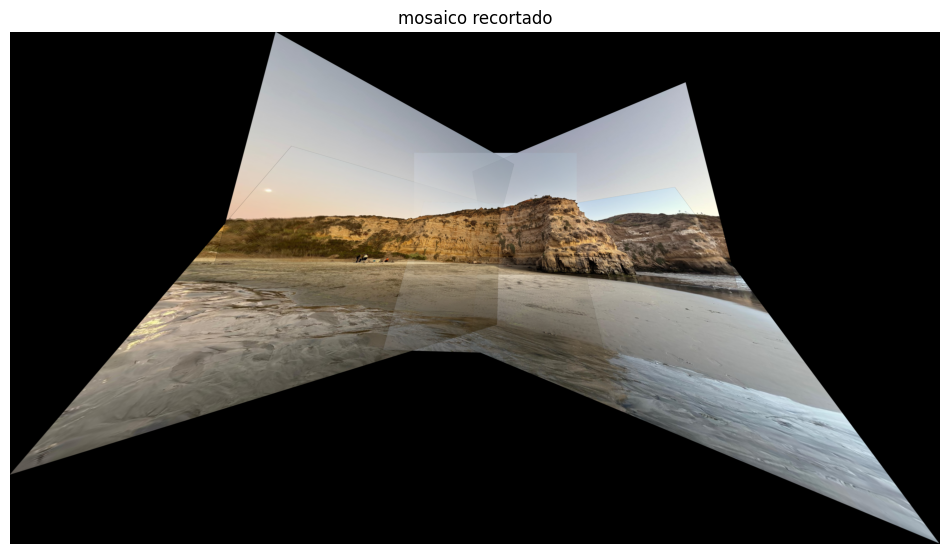

In [16]:
def recortar_bordes_negros(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 1, 255, cv2.THRESH_BINARY)
    contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contornos:
        return img
    x, y, w, h = cv2.boundingRect(max(contornos, key=cv2.contourArea))
    return img[y: y + h, x: x + w]


mosaico_recortado = recortar_bordes_negros(mosaico_referencia)

plt.figure(figsize=figsize)
plt.imshow(mosaico_recortado)
plt.title("mosaico recortado")
plt.axis("off")
plt.show()

## 5. (Opcional) Comparación con `cv2.Stitcher`

OpenCV trae un stitcher con bundle adjustment y blending automático. Sirve como referencia de "qué tan bien debería verse" comparado con la versión manual de arriba (que es la que tiene valor pedagógico para entender SIFT + homografías paso a paso).

In [ ]:
stitcher = cv2.Stitcher_create()
imagenes_bgr = [cv2.cvtColor(img, cv2.COLOR_RGB2BGR) for img in imagenes]
status, mosaico_cv = stitcher.stitch(imagenes_bgr)

if status == cv2.Stitcher_OK:
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(mosaico_cv, cv2.COLOR_BGR2RGB))
    plt.title("mosaico con cv2.Stitcher (referencia)")
    plt.axis("off")
    plt.show()
else:
    print(f"cv2.Stitcher no pudo armar el mosaico (status={status}). Códigos: 1=ERR_NEED_MORE_IMGS, 2=ERR_HOMOGRAPHY_EST_FAIL, 3=ERR_CAMERA_PARAMS_ADJUST_FAIL")